# Compression 04b — Codecs SOTA : le front de Pareto vitesse x taux

**Navigation** : [Index de la série](README.md) | [Compression-04 — ANS](Compression-04-ANS-Python.ipynb) | [Compression-05 — Compression des modèles](Compression-05-MLCompression-Python.ipynb)

> Sous-série `Compression` · Carnet 4b · Pli 6 de l'[EPIC #18706](https://github.com/jsboige/CoursIA/issues/18706)

Le carnet 04 s'est arrêté sur un constat qu'il ne pouvait pas refermer. Ses
codeurs entropiques — Huffman, rANS, tANS — collent à l'entropie **des
octets** du corpus, mesurée à 4,62 bits/octet. Et pourtant `zlib`, au banc
de la section 5 du carnet 04, descend **sous** cette entropie. Ce n'est pas
un paradoxe : `zlib` ne transmet pas les octets dont on mesure l'entropie.
Il commence par remplacer les répétitions par des références (le geste du
carnet 03), puis n'entropise que les **résidus** — dont l'entropie est plus
basse.

Ce carnet prend ce fil et le pousse jusqu'à la question qui décide
réellement en pratique : **quel codec choisir ?** La réponse courte — « le
meilleur » — n'a pas de sens, parce qu'un codec n'est pas un score, c'est
un **point dans un plan** : taux d'un côté, vitesse de l'autre. Nous allons
mesurer neuf codecs de production sur trois corpus, puis
**calculer** le front de Pareto — l'ensemble des codecs qu'aucun autre ne
bat sur les deux axes à la fois. Le résultat réserve une surprise : le
vainqueur change selon l'axe de vitesse qu'on regarde.

## 1. Le protocole, et pourquoi il faut un protocole

Trois précautions, sans lesquelles les chiffres ne veulent rien dire :

1. **Aller-retour vérifié, pas supposé.** Pour chaque codec et chaque
   corpus, le carnet décompresse et compare au tableau d'octets d'origine.
   Un codec qui compresse bien mais se décompresse mal n'est pas un codec :
   c'est un bug. L'assertion est le seul garde-fou qui distingue les deux.
2. **Débit mesuré par répétition, jamais sur un seul appel.** Un
   compresser de 128 Kio prend quelques centièmes de seconde : un
   `time.perf_counter()` unique mesure surtout le bruit du système
   d'exploitation. On répète jusqu'à accumuler au moins un quart de seconde,
   et on divise le volume total par le temps total.
3. **Ce que le banc mesure, et ce qu'il ne mesure pas.** Il mesure le
   **binding Python** sur cette machine, pas le codec en C. Un `zstd` qui plafonne à
   quelques dizaines de Mo/s dans ce banc et un `zstd` à plusieurs
   centaines de Mo/s en ligne de commande ne se contredisent pas : le premier paie la traversée Python. Les **taux**, eux,
   sont déterministes et se comparent directement.

## 2. Ce que l'environnement contient réellement

Avant de bancher quoi que ce soit, il faut savoir ce qui est là. La leçon
du carnet 04 vaut ici : ne jamais supposer qu'une bibliothèque est
disponible parce que son nom figure dans une spec.

In [1]:
import importlib
import sys

SONDAGE = {
    "zlib": "zlib",
    "bz2": "bz2",
    "lzma": "lzma",
    "zstandard": "zstandard",
    "brotli": "brotli",
    "lz4": "lz4",
    "snappy": "snappy",
    "openzl": "openzl",
}

print(f"Python {sys.version.split()[0]}")
print(f"{'module':<12}{'etat':<8}version / note")
for nom, module in SONDAGE.items():
    try:
        m = importlib.import_module(module)
        version = getattr(m, "__version__", None) or getattr(m, "ZSTD_VERSION", "n/a")
        origine = getattr(m, "__file__", "") or ""
        note = f"{version}"
        if nom == "snappy":
            note += f"  <- {origine}"
        print(f"{nom:<12}{'present':<8}{note}")
    except ModuleNotFoundError:
        print(f"{nom:<12}{'absent':<8}-")

Python 3.13.14
module      etat    version / note
zlib        present 1.0
bz2         present n/a
lzma        present n/a
zstandard   present 0.25.0
brotli      present 1.2.0
lz4         present 4.4.5


snappy      present 3.3.2  <- <USER_PATH>\AppData\Local\Programs\Python\Python313\Lib\site-packages\snappy\__init__.py
openzl      absent  -


### Lecture du résultat

Sept modules sur huit sont présents, mais **deux lignes doivent être lues
de près**, et l'une des deux est un piège :

- **`snappy` est présent et n'est pas le codec.** `import snappy` ramène
  **SnapPy**, la bibliothèque de topologie des variétés hyperboliques
  (elle expose `CensusKnots`, `DirichletDomain`…), installée sur cette
  machine pour un tout autre usage. Le codec Snappy de Google n'a rien à
  voir, et **ne fournit ni `compress` ni `decompress`** : l'importer et
  appeler `compress` lève un `AttributeError`. C'est une collision de noms
  entre deux paquets publiés sur PyPI, et le seul moyen de la voir est de
  sonder les **attributs**, pas le nom du module. Snappy sort donc du banc
  — non par absence, mais par homonymie.
- **`openzl` est absent.** L'Epic cite OpenZL 0.3.0 (blog du 2026-09-29 :
  Offset Encoding V-optimal, FieldLZ, PivCo-Huffman intégré) comme
  référence de l'état de l'art. Il n'existe **aucun binding Python
  publiable** : la référence reste documentaire dans ce carnet, ses
  apports sont décrits en section 9, aucun chiffre ne lui est attribué.

Les trois codecs de la distribution 7-Zip pinnée (`Lizard`, `Lz5`,
`Flzma2`) sont dans le même cas, pour une autre raison : leur accès passe
par le wrapper `SevenZipSharp` du sous-module, et la migration de la
distribution pinnée est encore ouverte (décision D6 de l'Epic, qui tient
aussi le pli 03b). Ils ne sont pas mesurés ici plutôt que simulés.

## 3. Trois corpus, trois régimes de compressibilité

Un codec se juge sur ce qu'on lui donne. Un seul corpus ne teste qu'un
régime : nous en prenons trois, choisis pour que les familles d'algorithme
se séparent.

- **`texte`** — 128 Kio du *Horla* de Maupassant, le corpus des carnets 01
  à 04. Alphabet restreint (88 symboles), énormément de répétitions : le
  terrain des deux couches, LZ **et** entropique.
- **`aleatoire`** — 64 Kio d'octets tirés uniformément (générateur seedé).
  Entropie maximale : **aucun** codec sans perte ne peut le réduire. C'est
  le témoin négatif — un codec qui prétend le compresser ment.
- **`structure`** — 128 Kio de flottants `float32` (un sinus et un cosinus
  échantillonnés), donc des octets à haute entropie marginale mais à forte
  redondance **positionnelle**. C'est le régime des données scientifiques :
  la redondance n'est pas dans la fréquence des octets, elle est dans leur
  arrangement.

In [2]:
import hashlib
from pathlib import Path

import numpy as np

chemin = Path("../GenAI/Audio/04-Applications/datasets/le_horla_1887.txt")
complet = chemin.read_bytes()
texte = complet[:131072]

generateur = np.random.default_rng(20260827)
aleatoire = generateur.integers(0, 256, 65536, dtype=np.uint8).tobytes()

t = np.arange(16384, dtype=np.float32)
structure = np.sin(t / 97.0).astype("<f4").tobytes() + np.cos(t / 231.0).astype("<f4").tobytes()

CORPUS = {"texte": texte, "aleatoire": aleatoire, "structure": structure}


def entropie(donnees):
    """Entropie marginale en bits par octet (ordre 0)."""
    n = len(donnees)
    freq = np.bincount(np.frombuffer(donnees, dtype=np.uint8), minlength=256) / n
    freq = freq[freq > 0]
    return float(-(freq * np.log2(freq)).sum())


print(f"source : {chemin.name} ({len(complet)} octets)")
for nom, donnees in CORPUS.items():
    print(f"{nom:<10} {len(donnees):>7} octets  H = {entropie(donnees):.4f} bits/octet"
          f"  {len(set(donnees)):>3} symboles  sha256 {hashlib.sha256(donnees).hexdigest()[:16]}")

source : le_horla_1887.txt (251105 octets)
texte       131072 octets  H = 4.6202 bits/octet   88 symboles  sha256 248fb4ec30c05351
aleatoire    65536 octets  H = 7.9974 bits/octet  256 symboles  sha256 222c8aa44096f247
structure   131072 octets  H = 7.2354 bits/octet  256 symboles  sha256 f051b3d81cc33ead


### Lecture du résultat

Les trois entropies dessinent les trois régimes, et une asymétrie
instructive :

- `texte` : 4,62 bits/octet sur 88 symboles seulement. L'alphabet est
  plat **et** restreint ; le maximum serait `log2(88)` = 6,46.
- `aleatoire` : 7,9974 — le plafond. À 64 Kio, l'estimateur d'entropie
  d'ordre 0 sous-estime légèrement le vrai 8,0 bits/octet : 256 symboles
  équiprobables ne sont jamais tous observés exactement le même nombre de
  fois sur un échantillon fini.
- `structure` : 7,2354. Voilà le cas intéressant. **L'entropie marginale
  est presque maximale** (0,76 bit sous le plafond), donc un codeur
  purement entropique comme tANS n'a presque rien à prendre. Toute la
  compressibilité de ces données est **positionnelle** — deux flottants
  voisins se ressemblent — et seule une couche LZ, qui compare des
  séquences, peut l'atteindre.

C'est déjà une prédiction falsifiable : sur `structure`, on attend les
codecs à forte couche LZ (`lzma`, `brotli`) nets devant les autres, et
`lz4` — qui cherche des correspondances courtes dans une petite fenêtre —
en difficulté. La section 5 bis la vérifie.

## 4. Le banc

Chaque codec est décrit par une paire `(compresser, décompresser)`. Le
débit est mesuré par répétition : on appelle la fonction jusqu'à avoir
accumulé au moins `DUREE_MIN` secondes, et on rapporte le volume total
traité divisé par le temps total. Les deux niveaux de zstd, brotli et lz4
sont inclus : ce sont les mêmes algorithmes avec des réglages différents,
et le carnet montre plus loin que ce réglage déplace un codec d'un régime
à l'autre.

In [3]:
import bz2
import lzma
import time
import zlib

import brotli
import lz4.frame
import zstandard as zstd

DUREE_MIN = 0.25

CODECS = {
    "lz4 (defaut)": (lambda b: lz4.frame.compress(b, compression_level=0), lz4.frame.decompress),
    "zstd -3": (lambda b: zstd.ZstdCompressor(level=3).compress(b), zstd.ZstdDecompressor().decompress),
    "zlib -9": (lambda b: zlib.compress(b, 9), zlib.decompress),
    "brotli -5": (lambda b: brotli.compress(b, quality=5), brotli.decompress),
    "brotli -11": (lambda b: brotli.compress(b, quality=11), brotli.decompress),
    "lzma -6": (lambda b: lzma.compress(b, preset=6), lzma.decompress),
    "bz2 -9": (lambda b: bz2.compress(b, 9), bz2.decompress),
    "zstd -19": (lambda b: zstd.ZstdCompressor(level=19).compress(b), zstd.ZstdDecompressor().decompress),
    "lz4 -16": (lambda b: lz4.frame.compress(b, compression_level=16), lz4.frame.decompress),
}


def debit(fonction, donnees, duree_min=DUREE_MIN):
    """Debit en Mo/s : repete l'appel jusqu'a duree_min secondes cumulees."""
    appels = 0
    debut = time.perf_counter()
    while time.perf_counter() - debut < duree_min:
        fonction(donnees)
        appels += 1
    ecoule = time.perf_counter() - debut
    return len(donnees) * appels / ecoule / 1024 / 1024


print(f"{len(CODECS)} codecs, duree minimale de mesure {DUREE_MIN} s par appel")

9 codecs, duree minimale de mesure 0.25 s par appel


## 5. Le banc sur le texte : neuf codecs, deux axes

Le tableau donne, pour chaque codec : le taux en bits par octet, l'écart à
l'entropie de la source, et les deux débits. L'aller-retour est vérifié
avant toute mesure de débit — un codec dont la décompression ne rend pas
l'original interrompt le carnet par une assertion, il ne produit pas de
chiffre.

In [4]:
RESULTATS = {}

for nom, (compresser, decompresser) in CODECS.items():
    compresse = compresser(texte)
    assert decompresser(compresse) == texte, f"aller-retour KO : {nom}"
    RESULTATS[nom] = {
        "bits_octet": 8 * len(compresse) / len(texte),
        "enc_Mo_s": debit(compresser, texte),
        "dec_Mo_s": debit(decompresser, compresse),
        "sha256": hashlib.sha256(compresse).hexdigest()[:16],
    }

H_TEXTE = entropie(texte)
print(f"{'codec':<14}{'bits/octet':>11}{'ecart a H':>11}{'enc. Mo/s':>11}{'dec. Mo/s':>11}   sha256")
print(f"{'(entropie H)':<14}{H_TEXTE:>11.4f}{'--':>11}{'--':>11}{'--':>11}")
for nom, r in sorted(RESULTATS.items(), key=lambda item: item[1]["bits_octet"]):
    print(f"{nom:<14}{r['bits_octet']:>11.4f}{r['bits_octet'] - H_TEXTE:>+11.4f}"
          f"{r['enc_Mo_s']:>11.2f}{r['dec_Mo_s']:>11.2f}   {r['sha256']}")

codec          bits/octet  ecart a H  enc. Mo/s  dec. Mo/s   sha256
(entropie H)       4.6202         --         --         --
bz2 -9             2.5970    -2.0232      11.23       9.32   8a094345bf525be0
brotli -11         2.8137    -1.8065       0.56      71.68   41dbf11cad87d6cd
lzma -6            2.8479    -1.7723       3.17      17.12   b807f3b6694a2adc
zstd -19           2.8889    -1.7313       2.08     116.96   592f8b9438842592
brotli -5          3.0664    -1.5538      25.22      89.99   f89fd5dcce190b0e
zlib -9            3.1364    -1.4838      12.41      90.20   2993c46cc08c61a7
zstd -3            3.2316    -1.3886      96.58     239.39   5fa87afd8c98ddfa
lz4 -16            3.7309    -0.8893       6.49     582.48   5ddbf9e279202319
lz4 (defaut)       5.1892    +0.5690     313.58    1558.20   f5c554403e805c3a


### Lecture du résultat

Trois faits, dans l'ordre de surprise croissante.

**1. Tous les codecs passent sous l'entropie de la source.** Le meilleur
taux, `bz2 -9` à 2,5970 bits/octet, est à 2,02 bits **sous** les 4,6202
mesurés en section 3. Ce n'est pas une violation de Shannon : l'entropie
d'ordre 0 ne compte que la fréquence des octets, alors que le texte a une
structure d'ordre supérieur, que la couche LZ exploite. Ce que le carnet 04
appelait « descendre sous H » est ici la règle, pas l'exception.

**2. `lz4`, à son réglage par défaut, ne compresse presque pas le texte** :
5,19 bits/octet, soit à peine mieux que l'entropie brute et **deux fois**
le taux de `bz2`. C'est le prix assumé de sa vitesse : c'est le seul codec
du banc à encoder à plus de 200 Mo/s — plus du double du suivant
(`zstd -3`), et plus de deux ordres de grandeur au-dessus du plus lent.
`lz4` au
niveau 16, en revanche, atteint 3,73 — le même algorithme, un autre point
du plan.

**3. L'ordre des taux n'est pas l'ordre des époques.** `bz2` (1996) bat
`brotli -11` (2016), `lzma` (1999) et `zstd -19` (2016) sur ce corpus.
`brotli -11` est même le plus **lent** du banc à l'encodage, pour un taux
moins bon que `bz2`. Un chiffre pareil ne dit pas que brotli est mauvais —
il dit que sur 128 Kio de français, la recherche de contexte intégrée de
bzip2 paie, et que le réglage 11 de brotli est calibré pour le web, pas
pour ce corpus. La section 6 tranche ce que « battre » veut dire.

## 5 bis. Le corpus décide du classement

Le carnet a annoncé trois régimes de compressibilité en section 3. Voici le
taux de chaque codec sur les trois corpus, côte à côte. Toutes les tailles
sont normalisées en bits par octet, donc comparables ; les deux corpus
d'étude font exactement 131 072 octets, le témoin en fait 65 536.

In [5]:
TAUX = {nom: {} for nom in CODECS}
for nom_corpus, donnees in CORPUS.items():
    for nom, (compresser, decompresser) in CODECS.items():
        compresse = compresser(donnees)
        assert decompresser(compresse) == donnees, f"aller-retour KO : {nom}/{nom_corpus}"
        TAUX[nom][nom_corpus] = 8 * len(compresse) / len(donnees)

entetes = list(CORPUS)
print(f"{'codec':<14}" + "".join(f"{c:>12}" for c in entetes) + f"{'rang texte':>12}")
for nom in sorted(TAUX, key=lambda n: TAUX[n]["texte"]):
    rang = sorted(TAUX, key=lambda n: TAUX[n]["texte"]).index(nom) + 1
    print(f"{nom:<14}" + "".join(f"{TAUX[nom][c]:>12.4f}" for c in entetes) + f"{rang:>12}")
print(f"{'(entropie)':<14}" + "".join(f"{entropie(CORPUS[c]):>12.4f}" for c in entetes))

codec                texte   aleatoire   structure  rang texte
bz2 -9              2.5970      8.0769      7.4608           1
brotli -11          2.8137      8.0005      6.1813           2
lzma -6             2.8479      8.0078      5.6243           3
zstd -19            2.8889      8.0012      7.2793           4
brotli -5           3.0664      8.0005      6.6963           5
zlib -9             3.1364      8.0032      7.3015           6
zstd -3             3.2316      8.0012      7.2825           7
lz4 -16             3.7309      8.0028      8.0016           8
lz4 (defaut)        5.1892      8.0028      8.0016           9
(entropie)          4.6202      7.9974      7.2354


### Lecture du résultat

La prédiction de la section 3 est vérifiée, et elle est plus nette que
prévu.

**Sur `structure`, le classement est presque l'inverse de celui du texte.**
`lzma -6` passe de la troisième à la **première** place (5,62 bits/octet),
`brotli -11` y reste **deuxième** (6,18), et surtout `lz4`, quel que soit
son niveau, reste **exactement à 8,00 bits/octet** : il ne trouve rien. Ce
n'est pas un réglage mal choisi, c'est structurel — `lz4` cherche des
séquences d'octets identiques dans une fenêtre courte, et deux flottants
voisins d'un sinus n'ont pas un seul octet en commun, seulement une
**proximité numérique** que seul un codec capable de modéliser la position
(via une fenêtre longue et un contexte) peut exploiter.

**`bz2`, vainqueur du texte, tombe au septième rang sur neuf sur `structure`** — ses
blocs de 900 Kio et son tri Burrows-Wheeler ne servent à rien sur des
données sans répétition lexicale. Le codec qui gagne sur un corpus perd
sur un autre : c'est la démonstration la plus directe qu'un banc à un seul
corpus ne mesure rien de transférable.

**Sur `aleatoire`, tous les codecs sont au-dessus de 8,00** et l'ordre du
tableau n'a plus aucun sens : les écarts de 0,0005 à 0,077 bits/octet sont
la taille des en-têtes, pas une performance. Nous y revenons en section 8.

## 6. Le front de Pareto, calculé

Un codec `A` **domine** un codec `B` s'il est au moins aussi bon sur les
deux axes et strictement meilleur sur l'un : `A` compresse mieux *et*
encode plus vite. Un codec dominé n'a aucune raison d'être choisi — sauf
contrainte hors modèle (mémoire, disponibilité, format imposé).

Le front de Pareto est l'ensemble des codecs non dominés. Nous le
calculons deux fois, avec **deux axes de vitesse différents** — encodage,
puis décodage —, parce que c'est exactement là que le choix se joue selon
qu'on archive ou qu'on sert.

In [6]:
def front_pareto(resultats, axe_vitesse):
    """Codecs non domines : taux minimal ET vitesse maximale a la fois."""
    tries = sorted(resultats.items(), key=lambda item: (item[1]["bits_octet"], -item[1][axe_vitesse]))
    front, meilleure_vitesse = [], -1.0
    for nom, r in tries:
        if r[axe_vitesse] > meilleure_vitesse:
            front.append(nom)
            meilleure_vitesse = r[axe_vitesse]
    return front


fronts = {axe: front_pareto(RESULTATS, f"{axe}_Mo_s") for axe in ("enc", "dec")}

for axe, etiquette in (("enc", "vitesse d'ENCODAGE"), ("dec", "vitesse de DECODAGE")):
    front = fronts[axe]
    domines = sorted(set(RESULTATS) - set(front), key=lambda n: RESULTATS[n]["bits_octet"])
    print(f"front sur ({etiquette}) : {len(front)} codecs non domines sur {len(RESULTATS)}")
    for nom in sorted(front, key=lambda n: RESULTATS[n]["bits_octet"]):
        r = RESULTATS[nom]
        print(f"   +  {nom:<14}{r['bits_octet']:>7.4f} b/o   {r[axe + '_Mo_s']:>9.2f} Mo/s")
    print(f"   domines : {', '.join(domines)}")
    print()

front sur (vitesse d'ENCODAGE) : 4 codecs non domines sur 9
   +  bz2 -9         2.5970 b/o       11.23 Mo/s
   +  brotli -5      3.0664 b/o       25.22 Mo/s
   +  zstd -3        3.2316 b/o       96.58 Mo/s
   +  lz4 (defaut)   5.1892 b/o      313.58 Mo/s
   domines : brotli -11, lzma -6, zstd -19, zlib -9, lz4 -16

front sur (vitesse de DECODAGE) : 6 codecs non domines sur 9
   +  bz2 -9         2.5970 b/o        9.32 Mo/s
   +  brotli -11     2.8137 b/o       71.68 Mo/s
   +  zstd -19       2.8889 b/o      116.96 Mo/s
   +  zstd -3        3.2316 b/o      239.39 Mo/s
   +  lz4 -16        3.7309 b/o      582.48 Mo/s
   +  lz4 (defaut)   5.1892 b/o     1558.20 Mo/s
   domines : lzma -6, brotli -5, zlib -9



### Lecture du résultat

Les deux fronts ne coïncident pas, et c'est tout le carnet.

**Sur l'axe encodage**, quatre codecs survivent : `bz2 -9` (le meilleur
taux), `brotli -5`, `zstd -3`, `lz4 (defaut)` (le plus rapide). Cinq sont
dominés, dont `brotli -11` et `zstd -19` — battus **en taux et en vitesse**
par `bz2`. Un archiviste qui ne peut encoder qu'une fois a donc une raison
mesurée de préférer bzip2 à deux codecs présentés comme modernes.

**Sur l'axe décodage**, le front change de membres : `brotli -11` y entre,
`brotli -5` en sort. Le même corpus, la même bibliothèque, deux niveaux de
réglage, et le verdict s'inverse selon qu'on paie l'encodage une fois ou le
décodage un million de fois. La raison est mesurable, et sa moitié solide
est **déterministe** : `zstd -19` compresse mieux que `brotli -5`
(2,8889 contre 3,0664 bits/octet) **et décode plus vite** — l'écart n'est
pas énorme, mais son signe est stable d'une exécution à l'autre. Il domine
donc `brotli -5` sur cet axe, alors
qu'il en était dominé sur l'encodage. Les taux sont reproductibles ; les
débits, eux, dépendent de la machine et du moment, et c'est pourquoi les
arguments de ce carnet s'appuient sur les taux.

`bz2 -9`, qui garde le meilleur taux, **ferme la marche du décodage, sous
les 10 Mo/s** : il n'est pas dominé (personne ne compresse mieux), mais il
est le premier à éliminer dès qu'un service décompresse à la volée.

**Ce que ce front ne dit pas, et qu'il faut lire dans la marge.** La
vitesse de décodage ne dépend presque pas du niveau de compression : `zstd
-3` et `zstd -19` décodent la même chose, et l'écart mesuré entre eux est
du bruit d'exécution, pas une propriété. C'est ce bruit qui fait entrer ou
sortir `zstd -3` du front d'un run à l'autre — ce carnet a vu les deux.
Il ne conclut donc rien d'un **comptage** de membres : il retient que
**deux fronts distincts existent et que leur intersection est strictement
plus petite que chacun d'eux**, ce qui suffit à établir qu'un choix de
codec à un seul chiffre n'a pas de sens.

Formulation honnête du résultat : sur ce corpus, **il n'existe pas de
meilleur codec**. Il existe un front d'archive et un front de service, de
tailles et de compositions différentes. Le choix est une décision, pas une
optimisation à une dimension.

## 7. Les quatre régimes

Le vocabulaire de l'Epic nomme quatre régimes en croisant les deux axes.
Nous les obtenons par mesure : le plan est coupé à la médiane du taux et à
la médiane de la vitesse d'encodage, et chaque codec tombe dans un
quadrant.

mediane du taux : 3.0664 bits/octet   mediane de vitesse : 11.23 Mo/s

lent-elu (4)
   bz2 -9         2.5970 b/o      11.23 Mo/s
   brotli -11     2.8137 b/o       0.56 Mo/s
   lzma -6        2.8479 b/o       3.17 Mo/s
   zstd -19       2.8889 b/o       2.08 Mo/s

lent-modeste (1)
   lz4 -16        3.7309 b/o       6.49 Mo/s

rapide-elu (1)
   brotli -5      3.0664 b/o      25.22 Mo/s

rapide-modeste (3)
   zlib -9        3.1364 b/o      12.41 Mo/s
   zstd -3        3.2316 b/o      96.58 Mo/s
   lz4 (defaut)   5.1892 b/o     313.58 Mo/s


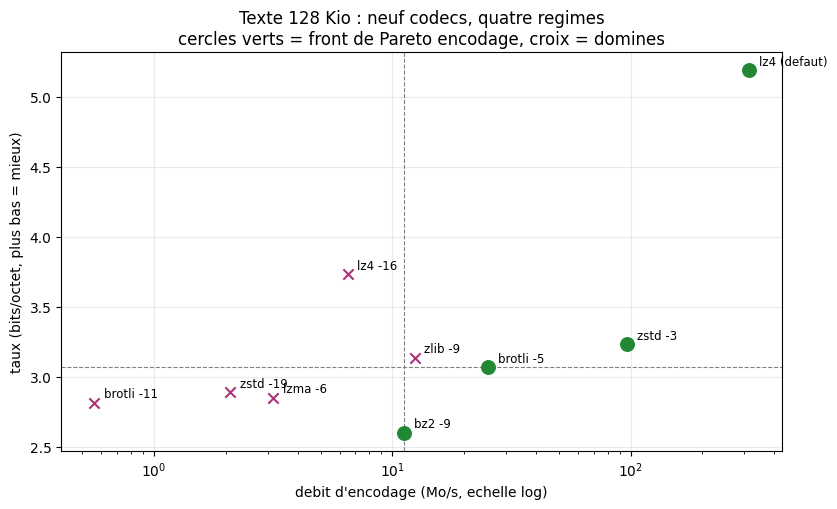

In [7]:
import matplotlib.pyplot as plt

noms = list(RESULTATS)
taux_median = float(np.median([RESULTATS[n]["bits_octet"] for n in noms]))
vitesse_mediane = float(np.median([RESULTATS[n]["enc_Mo_s"] for n in noms]))

REGIMES = {
    "lent-elu": lambda r: r["bits_octet"] <= taux_median and r["enc_Mo_s"] <= vitesse_mediane,
    "lent-modeste": lambda r: r["bits_octet"] > taux_median and r["enc_Mo_s"] <= vitesse_mediane,
    "rapide-elu": lambda r: r["bits_octet"] <= taux_median and r["enc_Mo_s"] > vitesse_mediane,
    "rapide-modeste": lambda r: r["bits_octet"] > taux_median and r["enc_Mo_s"] > vitesse_mediane,
}

print(f"mediane du taux : {taux_median:.4f} bits/octet   mediane de vitesse : {vitesse_mediane:.2f} Mo/s")
for regime, test in REGIMES.items():
    membres = [n for n in noms if test(RESULTATS[n])]
    print(f"\n{regime} ({len(membres)})")
    for nom in sorted(membres, key=lambda n: RESULTATS[n]["bits_octet"]):
        r = RESULTATS[nom]
        print(f"   {nom:<14}{r['bits_octet']:>7.4f} b/o   {r['enc_Mo_s']:>8.2f} Mo/s")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for nom in noms:
    r = RESULTATS[nom]
    dans_front = nom in fronts["enc"]
    ax.scatter(r["enc_Mo_s"], r["bits_octet"], s=95 if dans_front else 55,
               marker="o" if dans_front else "x",
               color="#228833" if dans_front else "#aa3377", zorder=3)
    ax.annotate(nom, (r["enc_Mo_s"], r["bits_octet"]),
                textcoords="offset points", xytext=(7, 4), fontsize=8.5)
ax.axhline(taux_median, color="grey", linestyle="--", linewidth=0.8)
ax.axvline(vitesse_mediane, color="grey", linestyle="--", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("debit d'encodage (Mo/s, echelle log)")
ax.set_ylabel("taux (bits/octet, plus bas = mieux)")
ax.set_title("Texte 128 Kio : neuf codecs, quatre regimes\n"
             "cercles verts = front de Pareto encodage, croix = domines")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Lecture du résultat

Ce tableau est le plus fragile du carnet, et c'est ce qu'il apprend.

**La coupe verticale est reproductible.** Les taux sont déterministes : le
même corpus, les mêmes bibliothèques, les mêmes nombres d'octets. La
médiane du taux vaut donc **3,0664 bits/octet à chaque exécution**, et elle
tombe sur le taux de `brotli -5`. Cinq codecs sont sous elle — `bz2 -9`
(2,5970), `brotli -11` (2,8137), `lzma -6` (2,8479), `zstd -19` (2,8889) et
`brotli -5` (3,0664) — et quatre au-dessus : `zlib -9` (3,1364), `zstd -3`
(3,2316), `lz4 -16` (3,7309), `lz4 (defaut)` (5,1892).

**La coupe horizontale ne l'est pas.** Une médiane calculée sur neuf points
tombe sur un point, et ce point appartient au peloton serré de `bz2 -9`,
`zlib -9` et `lz4 -16` — trois codecs dont la vitesse d'encodage se
chevauche largement d'une exécution à l'autre. Selon la seconde où l'on
mesure, c'est l'un ou l'autre qui passe au-dessus de la frontière.
Le quadrant de `bz2 -9` peut donc basculer de `lent-élu` à `rapide-élu`
sans qu'aucune propriété de bzip2 ait changé, et **le comptage par régime
n'est pas stable d'une exécution à l'autre** — ce n'est pas un résultat,
c'est une photographie. Les vitesses exactes de cette exécution sont dans
le tableau ci-dessus ; ce sont elles, et non un chiffre recopié ici, qui
situent les points.

**Ce qui survit à la ré-exécution**, et qui est donc la vraie leçon :

- `brotli -11`, `lzma -6` et `zstd -19` sont toujours sous la médiane de
  taux **et** toujours parmi les trois plus lents : le régime de
  l'archivage n'est pas discutable, il est structurel.
- `zstd -3` et `lz4 (defaut)` sont toujours au-dessus de la médiane de
  taux **et** toujours parmi les trois plus rapides : le régime du transit
  tient tout autant.
- Tout ce qui est **entre** ces deux familles est arbitré par la
  frontière, donc par le bruit : `bz2 -9` (le meilleur taux, mais lent) et
  `zlib -9` (DEFLATE au maximum de son effort, ni bon ni rapide — trente
  ans après sa spécification, 3,1364 bits/octet) sont les deux cas limites
  qui font basculer le tableau.

Le partage utile n'est donc pas entre quatre quadrants mais entre **deux
familles que la mesure sépare largement**, et une zone mitoyenne où le
classement appartient au seuil. `lz4 -16` y illustre le levier de réglage :
monter son niveau lui fait gagner 28 % de taux (3,7309 contre 5,1892) en
payant l'effort plusieurs dizaines de fois — un réglage ne change pas la
nature d'un algorithme, il déplace son point sur la même courbe.

La conséquence pratique dépasse ce tableau : **un quadrant est une grille de
lecture, pas une taxonomie**. Une grille a un seuil, un seuil se choisit, et
un choix de seuil décide du classement quand les points sont proches. C'est
pourquoi la section précédente **calcule** le front de Pareto : un front ne
dépend pas d'un seuil choisi, une grille si.

Le graphique porte l'essentiel : sur une échelle logarithmique en vitesse,
le front vert est une **marche d'escalier** de quatre points. Entre deux
marches, il n'y a rien à gagner — un codec intermédiaire est dominé, et le
choix se fait entre deux marches voisines, jamais au sein d'une marche.

## 8. Le témoin négatif : l'incompressible

Que fait un banc de compression sur des données qu'aucun codec sans perte
ne peut réduire ? Deux réponses sont inacceptables : qu'il n'y ait rien à
mesurer, et qu'un codec rende moins de 8 bits par octet. La première est
fausse — il y a beaucoup à mesurer ; la seconde serait le signe d'un banc
cassé.

In [8]:
print(f"{'codec':<14}{'bits/octet':>11}{'surcout':>9}{'enc. Mo/s':>11}{'dec. Mo/s':>11}")
for nom, (compresser, decompresser) in CODECS.items():
    compresse = compresser(aleatoire)
    assert decompresser(compresse) == aleatoire, f"aller-retour KO : {nom}"
    bits = 8 * len(compresse) / len(aleatoire)
    print(f"{nom:<14}{bits:>11.4f}{bits - 8:>+9.4f}"
          f"{debit(compresser, aleatoire):>11.2f}{debit(decompresser, compresse):>11.2f}")
print(f"\nentropie de la source : {entropie(aleatoire):.4f} bits/octet")

codec          bits/octet  surcout  enc. Mo/s  dec. Mo/s


lz4 (defaut)       8.0028  +0.0028    6202.62   13693.64


zstd -3            8.0012  +0.0012    1489.40   14578.68


zlib -9            8.0032  +0.0032      29.94    1487.73


brotli -5          8.0005  +0.0005      56.74    8391.48


brotli -11         8.0005  +0.0005       2.71    9982.72


lzma -6            8.0078  +0.0078       3.73     524.24


bz2 -9             8.0769  +0.0769       8.68      21.45


zstd -19           8.0012  +0.0012       8.42   25485.92


lz4 -16            8.0028  +0.0028      42.42   13448.26

entropie de la source : 7.9974 bits/octet


### Lecture du résultat

Aucun codec ne descend sous 8,00 bits/octet : le banc est sain, et le
théorème tient. Tous **dépassent** 8,00, d'un surcoût qui va de 0,0005
(`brotli -11`) à 0,077 (`bz2 -9`) bit/octet — c'est l'en-tête du format
plus les quelques octets que le codec ajoute quand il ne trouve rien à
retirer. Sur 64 Kio, `bz2` ajoute 0,077 bit/octet, soit environ 630 octets
de structures internes : le prix d'un format à blocs.

Deux chiffres du tableau méritent qu'on s'y arrête, parce qu'ils sont des
artefacts et non des performances :

- les débits de **décodage** atteignent des valeurs absurdes (plusieurs
  milliers de Mo/s). Un décodeur qui n'a rien à défaire se contente de
  recopier le bloc stocké — on mesure la vitesse de `memcpy`, pas celle du
  codec.
- `lz4` encode l'incompressible **plusieurs fois plus vite** que sur le
  texte, pour cette même raison : son chemin rapide détecte l'absence de
  correspondance et stocke.

C'est la raison pour laquelle la section 5 mesurait les débits sur le
**texte** : un banc de compression qui ne mesure que de l'incompressible
mesure la mémoire du système.

## 9. Le levier du niveau : un codec traverse les régimes

Le carnet a présenté chaque codec comme un point. C'est une simplification
commode : la plupart exposent un **niveau**, et le niveau déplace le point
sur la courbe. Zstandard est le cas d'école — un seul algorithme, de
-réglages qui vont du transit au quasi-archivage.

 niveau  bits/octet  enc. Mo/s  dec. Mo/s  vs bz2 -9
      1      3.5406     189.30     312.04    +0.9436
      3      3.2316      91.72      61.35    +0.6346
      6      3.1097      23.09     130.82    +0.5127
      9      3.0392      13.77     149.49    +0.4423
     12      3.0092       7.96     177.86    +0.4122
     15      2.9100       3.85     130.21    +0.3130
     19      2.8889       1.41     101.81    +0.2919
     22      2.8889       1.51     147.05    +0.2919


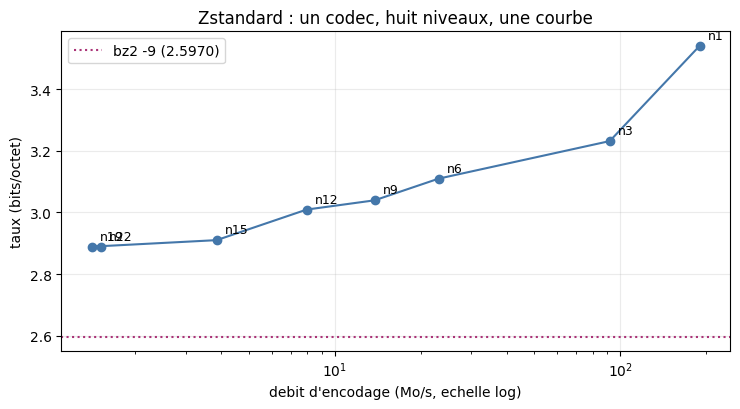

In [9]:
NIVEAUX = [1, 3, 6, 9, 12, 15, 19, 22]
balayage = []
for niveau in NIVEAUX:
    compresse = zstd.ZstdCompressor(level=niveau).compress(texte)
    assert zstd.ZstdDecompressor().decompress(compresse) == texte, f"aller-retour KO : zstd {niveau}"
    balayage.append({
        "niveau": niveau,
        "bits_octet": 8 * len(compresse) / len(texte),
        "enc_Mo_s": debit(lambda b, n=niveau: zstd.ZstdCompressor(level=n).compress(b), texte),
        "dec_Mo_s": debit(zstd.ZstdDecompressor().decompress, compresse),
    })

reference = RESULTATS["bz2 -9"]["bits_octet"]
print(f"{'niveau':>7}{'bits/octet':>12}{'enc. Mo/s':>11}{'dec. Mo/s':>11}{'vs bz2 -9':>11}")
for r in balayage:
    print(f"{r['niveau']:>7}{r['bits_octet']:>12.4f}{r['enc_Mo_s']:>11.2f}"
          f"{r['dec_Mo_s']:>11.2f}{r['bits_octet'] - reference:>+11.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot([r["enc_Mo_s"] for r in balayage], [r["bits_octet"] for r in balayage],
        "-o", color="#4477aa", zorder=3)
for r in balayage:
    ax.annotate(f"n{r['niveau']}", (r["enc_Mo_s"], r["bits_octet"]),
                textcoords="offset points", xytext=(6, 5), fontsize=9)
ax.axhline(reference, color="#aa3377", linestyle=":", label=f"bz2 -9 ({reference:.4f})")
ax.set_xscale("log")
ax.set_xlabel("debit d'encodage (Mo/s, echelle log)")
ax.set_ylabel("taux (bits/octet)")
ax.set_title("Zstandard : un codec, huit niveaux, une courbe")
ax.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### Lecture du résultat

La courbe a la forme attendue — le taux s'améliore quand la vitesse chute —
mais elle porte deux enseignements qu'aucun tableau de benchmarks
commercial ne donne :

- **Le rendement s'effondre bien avant le dernier niveau.** Entre le
  niveau 1 et le niveau 6, zstd gagne 0,43 bit/octet (3,5406 → 3,1097) en
  abandonnant l'essentiel de sa vitesse d'encodage — la colonne `enc. Mo/s`
  du tableau donne le rapport exact pour cette exécution. Entre le
  niveau 15 et le niveau 22, il gagne **0,02 bit/octet** (2,9100 → 2,8889),
  c'est-à-dire presque rien, en payant encore un facteur sur ce qui lui
  restait. Le dernier
  cran du réglage coûte cher pour presque rien : c'est la définition d'un
  réglage mal choisi.
- **Les niveaux 19 et 22 rendent la même taille** sur ce corpus — à
  128 Kio, la fenêtre et les structures de niveau 22 n'ont plus rien à
  exploiter que le niveau 19 n'ait déjà trouvé. Deux points du tableau,
  un seul point de la courbe.

Et le point qui referme le carnet : **aucun niveau de zstd n'atteint `bz2
-9` en taux**. La colonne « vs bz2 -9 » reste positive de bout en bout.
Zstandard gagne partout ailleurs — en vitesse de décodage, en réglabilité,
en ratio vitesse/taux — mais sur 128 Kio de français, la fenêtre de bzip2
et son codage par blocs restent devant. Ce n'est pas un classement
définitif : c'est la démonstration que « meilleur codec » n'a pas de sens
hors d'un corpus et d'un axe.

### Ce qu'OpenZL apporte, et pourquoi il n'est pas au banc

L'Epic cite OpenZL 0.3.0 comme représentant de l'état de l'art 2025-2026.
Trois apports sont documentés par sa spécification, et aucun n'est mesuré
ici — aucun binding Python n'existe (`import openzl` : `ModuleNotFoundError`,
section 2) :

- **Offset Encoding V-optimal** — coder les décalages LZ par un code
  optimal plutôt qu'un code fixe, ce qui attaque précisément le surcoût que
  la section 8 mesure sur les blocs courts ;
- **FieldLZ** — séparer les données en champs (colonnes d'un enregistrement)
  et compresser chaque champ avec son propre codec, la réponse au régime
  `structure` de la section 3 ;
- **PivCo-Huffman** — Huffman sur arbres d'ondelettes pour un décodage
  SIMD, c'est-à-dire l'attaque du mur de la section 9 : améliorer le
  décodage sans payer le taux.

Ce sont des directions, pas des chiffres. Le carnet les nomme pour que le
lecteur sache ce qui manque, sans leur prêter une mesure qu'il n'a pas
faite.

## 10. Exercices

Trois exercices, du calcul au diagnostic. Chaque fonction squelette
retourne `None` tant qu'elle n'est pas complétée : le carnet s'exécute de
bout en bout dans cet état.

In [10]:
# Exercice 1 -- Le front de Pareto a trois axes
#
# Le carnet a calcule deux fronts : (taux, encodage) et (taux, decodage).
# Un archiviste, lui, a trois contraintes : il veut le meilleur taux, un
# encodage supportable ET un decodage supportable. Le front a trois
# dimensions n'est plus une marche d'escalier : un codec peut y entrer en
# etant mauvais sur un axe, du moment qu'aucun autre ne le bat sur les trois.

def front_trois_axes(resultats, seuil_enc, seuil_dec):
    """TODO etudiant : codecs non domines sur (bits_octet, enc_Mo_s, dec_Mo_s),
    restreints a ceux qui passent les deux seuils de vitesse.

    Indice : un codec A domine B si A a un bits_octet <=, un enc_Mo_s >= et
    un dec_Mo_s >=, avec au moins une inegalite stricte. Comparer toutes les
    paires est O(n^2) et n = 9 : c'est la bonne facon d'ecrire la definition.
    Indice : avec seuil_enc=10 et seuil_dec=50, la reponse doit contenir plus
    d'un codec -- le front a trois axes est plus permissif que celui a deux.
    """
    return None


res_exo1 = front_trois_axes(RESULTATS, seuil_enc=10.0, seuil_dec=50.0)
if res_exo1 is None:
    print("Exercice a completer : front_trois_axes")
else:
    print(f"front a trois axes (enc >= 10 Mo/s, dec >= 50 Mo/s) : {len(res_exo1)} codecs")
    for nom in res_exo1:
        r = RESULTATS[nom]
        print(f"   {nom:<14}{r['bits_octet']:>7.4f} b/o  {r['enc_Mo_s']:>8.2f}  {r['dec_Mo_s']:>8.2f}")

Exercice a completer : front_trois_axes


In [11]:
# Exercice 2 -- Le corpus change le classement
#
# La section 3 predit que sur `structure` (entropie marginale presque
# maximale, redondance purement positionnelle), les codecs a forte couche LZ
# passent devant et que lz4 decroche. Verifiez-le, et quantifiez l'ecart
# avec le classement obtenu sur le texte.

def classement(donnees, codecs):
    """TODO etudiant : renvoyer la liste des noms de codecs tries par
    bits/octet croissant sur `donnees`, apres avoir verifie l'aller-retour.

    Indice : reutilisez `debit` seulement si vous voulez aussi les vitesses ;
    le classement ne demande que la taille compressee.
    Indice : `structure` fait 131 072 octets, comme le texte -- les deux
    classements sont donc comparables sans normalisation.
    """
    return None


res_exo2 = classement(structure, CODECS)
if res_exo2 is None:
    print("Exercice a completer : classement")
else:
    print("classement sur 'structure' (bits/octet croissant) :")
    for rang, nom in enumerate(res_exo2, start=1):
        print(f"   {rang}. {nom}")

Exercice a completer : classement


In [12]:
# Exercice 3 -- Le seuil ou un codec cesse d'etre utile
#
# Sur l'incompressible, tous les codecs depassent 8 bits/octet : ils
# RALONGENT les donnees. Un service qui compresse a l'aveugle paie donc
# pour rien, et parfois paie plus cher que de ne rien faire. Mesurez a
# partir de quelle entropie de source chaque codec devient perdant.

def seuil_perdant(codec, fractions):
    """TODO etudiant : pour chaque fraction f de `fractions` (proportion
    d'octets uniformes melanges a du texte), construire un melange, mesurer
    bits/octet avec `codec` et rapporter un dict {f: bits_octet}.

    Indice : construisez le melange comme
    `(texte[:int(len(texte)*f)] + aleatoire[:int(len(texte)*(1-f))])` --
    la taille totale reste constante, seule la part incompressible varie.
    Indice : tracez ensuite les courbes ; le croisement de la droite a 8
    bits/octet est le seuil cherche. Un codec qui stocke (lz4) reste sous 8
    beaucoup plus longtemps qu'un codec a en-tete lourd (bz2).
    """
    return None


res_exo3 = seuil_perdant(CODECS["bz2 -9"], [0.0, 0.25, 0.5, 0.75, 1.0])
if res_exo3 is None:
    print("Exercice a completer : seuil_perdant")
else:
    for f in sorted(res_exo3):
        print(f"part incompressible {f:4.0%} : {res_exo3[f]:.4f} bits/octet")

Exercice a completer : seuil_perdant


## À retenir

- **Un codec n'est pas un score, c'est un point.** Le classer sur le taux
  seul, ou sur la vitesse seule, produit une réponse fausse dans les deux
  cas. Le carnet a calculé le front de Pareto plutôt que de désigner un
  vainqueur, et le front **change de membres** selon qu'on regarde la
  vitesse d'encodage ou celle de décodage.
- **La couche LZ explique l'écart au carnet 04.** Les codeurs entropiques
  nus collent à l'entropie des octets (4,62 bits/octet sur le texte) ; les
  codecs de production passent 2 bits **sous** cette valeur parce qu'ils ne
  transmettent pas les octets dont on mesure l'entropie. Le carnet 03 avait
  raison avant le carnet 04, et les deux ne se contredisent pas : ils
  mesurent deux choses.
- **L'âge d'un algorithme ne prédit pas son rang.** Sur 128 Kio de
  français, `bz2` (1996) bat `brotli -11`, `lzma -6` et `zstd -19` en taux
  **et** en vitesse d'encodage. Ce n'est pas un verdict universel : c'est
  un résultat sur un corpus, et il suffit de changer de corpus (exercice 2)
  pour le voir bouger.
- **Le niveau est un levier, pas une qualité.** Un même codec traverse
  plusieurs régimes selon son réglage — et le dernier cran coûte cher pour
  presque rien : entre les niveaux 15 et 22 de zstd, 0,02 bit/octet pour
  plus de deux fois moins de vitesse.
- **Un banc se vérifie avant de mesurer.** Aller-retour octet-exact
  asserté, débit par répétition, et lecture critique des chiffres absurdes :
  les milliers de Mo/s de décodage sur l'incompressible mesurent `memcpy`,
  pas un codec.